# Hotel Model Explorer
Provisional experiment on the Data Lead handover. Charts with actual cancellations use Choose only. The August CSV is a retrospective demo. It contains no actual outcomes.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
input_file = root / "data" / "cleaned_hotels_bin1.csv"
results = root / "results"
bookings = pd.read_csv(input_file, low_memory=False)
selection = json.loads((results / "selection.json").read_text(encoding="utf-8"))
print(f"Source: {input_file.name}")
print(f"{len(bookings):,} bookings, {len(bookings.columns)} columns")
print(bookings.isna().sum().loc[lambda counts: counts > 0].to_string())
print("Predictors:", ", ".join(selection["features"]))

Source: cleaned_hotels_bin1.csv
117,430 bookings, 32 columns
children         4
country        467
agent        15391
company     111051
Predictors: hotel, distribution_channel, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled


## Choose bookings by hotel
Only July–December 2016 outcomes appear in this chart.

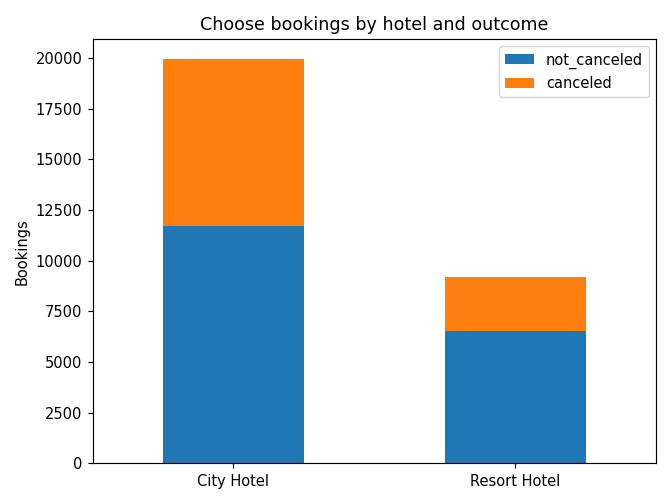

              bookings  canceled  not_canceled
hotel                                         
City Hotel       19929      8210         11719
Resort Hotel      9178      2641          6537


In [2]:
choose_bookings = bookings.loc[bookings["arrival_date_year"].eq(2016)
                              & bookings["arrival_date_month"].isin(
                                  ["July", "August", "September", "October", "November", "December"]
                              )]
hotel = choose_bookings.groupby("hotel")["is_canceled"].agg(bookings="size", canceled="sum")
hotel["not_canceled"] = hotel["bookings"] - hotel["canceled"]
ax = hotel[["not_canceled", "canceled"]].plot.bar(stacked=True, rot=0)
ax.set(title="Choose bookings by hotel and outcome", ylabel="Bookings", xlabel="")
plt.tight_layout()
plt.show()
print(hotel.to_string())

## Which method won?
The winner has the lowest loss among the rows that pass the walking ceiling.

In [3]:
comparison = pd.read_csv(results / "choose_model_comparison.csv")
print(comparison.to_string(index=False))
winner = selection["selected"]
buffer = selection["buffers"][winner]
print(f"Selected {winner} with a buffer of {buffer} rooms.")

  method      auc    brier  nightly_mae  buffer   cost_eur  empty_rooms  walked_guests  walks_per_1000  ceiling_met  nights  saving_vs_flat_eur  selected
    flat 0.557343 0.230918     9.109037      16 2424573.58         5472            180            9.86         True     368                0.00     False
  lookup 0.603900 0.224910     8.743411      16 2412360.85         5447            181            9.91         True     368            12212.73     False
logistic 0.616355 0.226211     9.302253       6 1968070.40         4632            175            9.59         True     368           456503.18      True
  forest 0.612421 0.226099     9.260926       7 2080298.34         4879            159            8.71         True     368           344275.24     False
Selected logistic with a buffer of 6 rooms.


## How close were the nightly estimates?
Each point is one Choose hotel-night. Points on the dashed line have equal expected and actual cancellation counts.

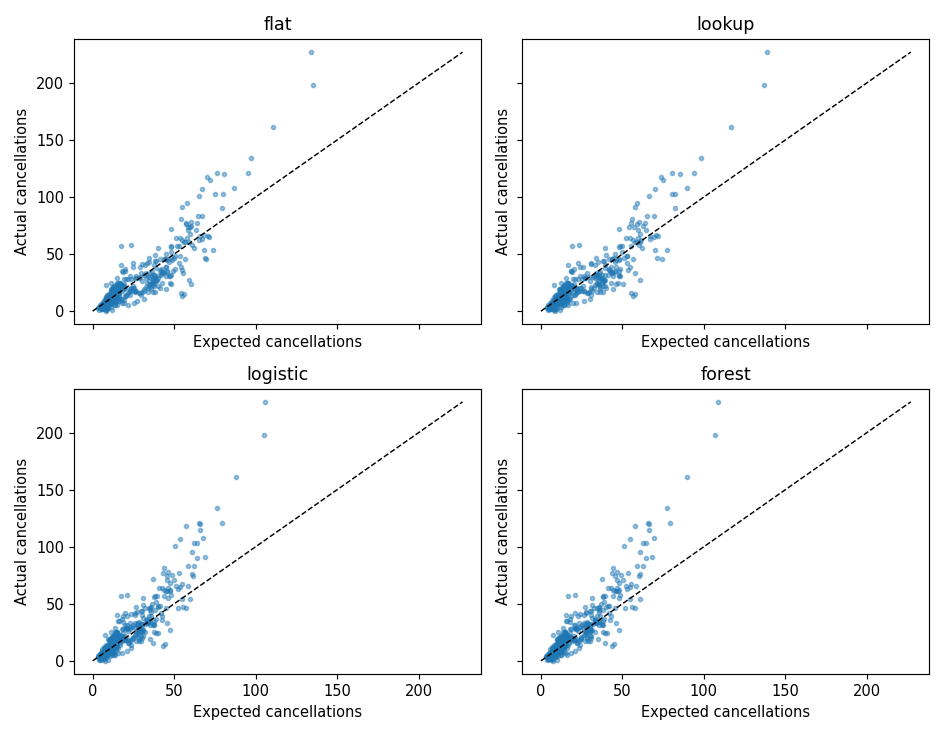

In [4]:
nights = pd.read_csv(results / "choose_nightly_predictions.csv")
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
upper = max(nights["expected"].max(), nights["cancelled"].max())
for ax, (method, rows) in zip(axes.flat, nights.groupby("method", sort=False)):
    ax.scatter(rows["expected"], rows["cancelled"], s=8, alpha=0.45)
    ax.plot([0, upper], [0, upper], "k--", linewidth=1)
    ax.set(title=method, xlabel="Expected cancellations", ylabel="Actual cancellations")
fig.tight_layout()
plt.show()

## What does the buffer change?
Dots show the selected buffer for each model. The full range is in the CSV. The chart zooms in on the useful range near the chosen buffers.

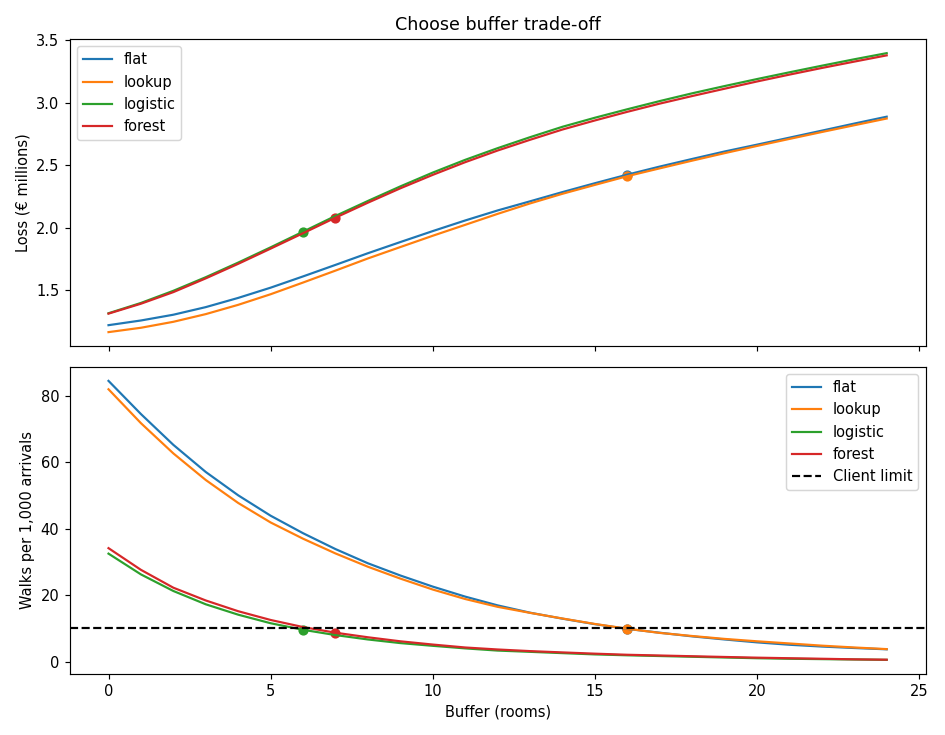

In [5]:
grid = pd.read_csv(results / "choose_buffer_grid.csv")
fig, (cost_ax, walk_ax) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
limit = comparison["buffer"].max() + 8
for method, rows in grid.loc[grid["buffer"].le(limit)].groupby("method", sort=False):
    cost_ax.plot(rows["buffer"], rows["cost_eur"] / 1_000_000, label=method)
    walk_ax.plot(rows["buffer"], rows["walks_per_1000"], label=method)
    best = comparison.loc[comparison["method"].eq(method)].iloc[0]
    cost_ax.scatter(best["buffer"], best["cost_eur"] / 1_000_000)
    walk_ax.scatter(best["buffer"], best["walks_per_1000"])
cost_ax.set(title="Choose buffer trade-off", ylabel="Loss (€ millions)")
cost_ax.legend()
walk_ax.axhline(10, color="black", linestyle="--", label="Client limit")
walk_ax.legend()
walk_ax.set(xlabel="Buffer (rooms)", ylabel="Walks per 1,000 arrivals")
fig.tight_layout()
plt.show()

## Sample recommendations
The rows below use the final August booking list and the saved model. No guest outcomes enter the recommendation.

In [6]:
demo = pd.read_csv(results / "nightly_recommendations.csv")
assert len(demo) == 28
print(demo.head(6).to_string(index=False))

       hotel arrival_date  bookings  expected_cancellations  safety_buffer  recommended_oversell
  City Hotel   2017-08-18       121               39.361233              6                    33
Resort Hotel   2017-08-18        60               13.367268              6                     7
  City Hotel   2017-08-19       122               40.494061              6                    34
Resort Hotel   2017-08-19        66               15.055013              6                     9
  City Hotel   2017-08-20       101               33.173629              6                    27
Resort Hotel   2017-08-20        56               13.168574              6                     7
